# Product Analytics

## Objective

The objective of this notebook is to analyze product feature usage
to understand how customers interact with the SaaS platform.

## Business Questions

1. Which product features are used most frequently?
2. Which features account for the highest total usage?
3. How much time do customers spend using different features?
4. Which features experience the most errors?

## Dataset

The analysis begins with the feature usage dataset, which contains
usage dates, feature names, usage counts, usage duration, error counts,
and subscription identifiers.

Load Dataset

In [29]:
import pandas as pd

feature_usage=pd.read_csv(r"../data/raw/ravenstack_feature_usage.csv")

display(feature_usage.head())

,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False
2,U-096807,S-f29e7f,2023-12-07,feature_3,9,1458,0,False
3,U-6b1580,S-be655e,2024-07-28,feature_40,5,2085,0,False
4,U-720a29,S-f9b1d0,2024-12-02,feature_12,12,900,0,False


Dataset Infomation

In [30]:
print("Datasets shape no of rows:",feature_usage.shape[0],", no of columns:",feature_usage.shape[1])
print("feature_usage Columns:",feature_usage.columns.to_list())
print("Datasets infromation:")
print(feature_usage.dtypes)
display(feature_usage.head())

Datasets shape no of rows: 25000 , no of columns: 8
feature_usage Columns: ['usage_id', 'subscription_id', 'usage_date', 'feature_name', 'usage_count', 'usage_duration_secs', 'error_count', 'is_beta_feature']
Datasets infromation:
usage_id                 str
subscription_id          str
usage_date               str
feature_name             str
usage_count            int64
usage_duration_secs    int64
error_count            int64
is_beta_feature         bool
dtype: object


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False
2,U-096807,S-f29e7f,2023-12-07,feature_3,9,1458,0,False
3,U-6b1580,S-be655e,2024-07-28,feature_40,5,2085,0,False
4,U-720a29,S-f9b1d0,2024-12-02,feature_12,12,900,0,False


Check missing values

In [32]:
print("Missing values in each column:")
print(feature_usage.isnull().sum())

Missing values in each column:
usage_id               0
subscription_id        0
usage_date             0
feature_name           0
usage_count            0
usage_duration_secs    0
error_count            0
is_beta_feature        0
dtype: int64


Check duplicate records

In [33]:
dupilcate_count=feature_usage.duplicated().sum()
print("Completely dupilcate rows:",dupilcate_count)

Completely dupilcate rows: 0


Inspect numerical columns

In [34]:
display(
    feature_usage.describe(include="number")
)

,usage_count,usage_duration_secs,error_count
count,25000.000000,25000.000000,25000.000000
mean,10.021000,3042.202880,0.564280
std,3.143729,2056.544615,1.012595
min,0.000000,0.000000,0.000000
25%,8.000000,1350.000000,0.000000
50%,10.000000,2760.000000,0.000000
75%,12.000000,4400.000000,1.000000
max,26.000000,12696.000000,8.000000


Q1

Available features

In [35]:
print("Unique Features name")

display(feature_usage["feature_name"].unique())

print("Number of unique features:", feature_usage["feature_name"].nunique())

Unique Features name


<StringArray>
['feature_20',  'feature_5',  'feature_3', 'feature_40', 'feature_12',
 'feature_14', 'feature_34', 'feature_27', 'feature_18', 'feature_28',
 'feature_36', 'feature_35', 'feature_25',  'feature_4', 'feature_24',
 'feature_37',  'feature_7', 'feature_15', 'feature_30', 'feature_39',
 'feature_19',  'feature_6', 'feature_21',  'feature_1', 'feature_22',
 'feature_38', 'feature_29', 'feature_23', 'feature_31', 'feature_16',
  'feature_9', 'feature_26', 'feature_11', 'feature_10', 'feature_33',
  'feature_8', 'feature_13', 'feature_32', 'feature_17',  'feature_2']
Length: 40, dtype: str

Number of unique features: 40


Calculate total usage by feature

In [36]:
feature_usage_summary=(
    feature_usage
    .groupby("feature_name")["usage_count"]
    .sum()
    .reset_index()
    .sort_values("usage_count",ascending=False)    
)

display(feature_usage_summary)

,feature_name,usage_count
25,feature_32,6686
6,feature_15,6621
36,feature_6,6546
12,feature_20,6541
27,feature_34,6536
3,feature_12,6534
2,feature_11,6533
11,feature_2,6525
31,feature_38,6478
18,feature_26,6470


In [37]:
top_5_features = feature_usage_summary.head(5)

display(top_5_features)

,feature_name,usage_count
25,feature_32,6686
6,feature_15,6621
36,feature_6,6546
12,feature_20,6541
27,feature_34,6536


Visualize the top five features

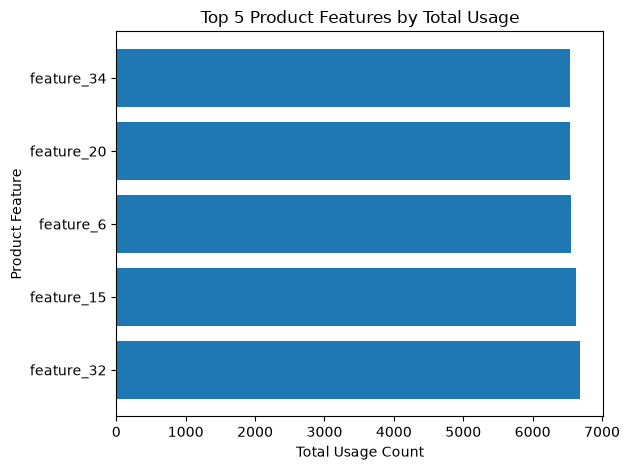

In [38]:
import matplotlib.pyplot as plt
plt.barh(
    top_5_features["feature_name"],
    top_5_features["usage_count"]
)
plt.title("Top 5 Product Features by Total Usage")
plt.xlabel("Total Usage Count")
plt.ylabel("Product Feature")

plt.tight_layout()
plt.show()



- The dataset contains 40 unique product features.
- `feature_32` recorded the highest total usage, with 6,686.
- `feature_15` ranked second, followed by `feature_6`,
  `feature_20`, and `feature_34`.
- These results identify the most frequently recorded feature
  usage.

Q2

Measure Feature Adoption

In [39]:
feature_adoption=(
    feature_usage
    .groupby("feature_name")["subscription_id"]
    .nunique()
    .reset_index()
)

feature_adoption.columns=[
    "feature_name",
    "unique_subscriptions"
]

feature_adoption=feature_adoption.sort_values(
    "unique_subscriptions",
    ascending=False
)

display(feature_adoption)

,feature_name,unique_subscriptions
3,feature_12,624
18,feature_26,616
25,feature_32,614
27,feature_34,613
8,feature_17,613
31,feature_38,610
11,feature_2,607
2,feature_11,606
6,feature_15,606
29,feature_36,604


In [40]:
top_5_adoptions=feature_adoption.head(5)
print("Top_5_adoptions")
display(top_5_adoptions)

Top_5_adoptions


,feature_name,unique_subscriptions
3,feature_12,624
18,feature_26,616
25,feature_32,614
27,feature_34,613
8,feature_17,613


In [41]:
feature_comparison=feature_usage_summary.merge(
    feature_adoption,
    on="feature_name",
    how="inner"
)

feature_comparison=feature_comparison.sort_values(
    "usage_count",
    ascending=False
    )
print("Feature_comparison")
display(feature_comparison.head(10))

Feature_comparison


,feature_name,usage_count,unique_subscriptions
0,feature_32,6686,614
1,feature_15,6621,606
2,feature_6,6546,604
3,feature_20,6541,590
4,feature_34,6536,613
5,feature_12,6534,624
6,feature_11,6533,606
7,feature_2,6525,607
8,feature_38,6478,610
9,feature_26,6470,616


Analyze usage duration and errors

Calculate total usage duration by feature

In [42]:
feature_duration=(
    feature_usage
    .groupby("feature_name")["usage_duration_secs"]
    .sum()
    .reset_index()
)

feature_duration=feature_duration.sort_values(
    "usage_duration_secs",
    ascending=False
)

display(feature_duration.head(10))

,feature_name,usage_duration_secs
16,feature_24,2070250
3,feature_12,2061481
25,feature_32,2052316
36,feature_6,2013972
2,feature_11,2012779
27,feature_34,2006721
18,feature_26,1976377
33,feature_4,1968622
6,feature_15,1966988
26,feature_33,1963278


In [26]:
feature_duration["usage_duration_hours"]=(
    feature_duration["usage_duration_secs"]/3600
    )

display(feature_duration.head(10))

,feature_name,usage_duration_secs,usage_duration_hours
16,feature_24,2070250,575.069444
3,feature_12,2061481,572.633611
25,feature_32,2052316,570.087778
36,feature_6,2013972,559.436667
2,feature_11,2012779,559.105278
27,feature_34,2006721,557.422500
18,feature_26,1976377,548.993611
33,feature_4,1968622,546.839444
6,feature_15,1966988,546.385556
26,feature_33,1963278,545.355000


### Key Findings
- `feature_24` has the highest total recorded usage duration, at approximately 575 hours.
- `feature_12` appears among the top features for both subscription adoption and usage duration.
- `feature_32` ranks highly in total usage, subscription adoption and duration.

Find the features with the most errors

- Calculate total errors per feature

In [51]:
feature_errors = (
    feature_usage
    .groupby("feature_name")["error_count"]
    .sum()
    .reset_index()
    .sort_values("error_count", ascending=False)
)

display(feature_errors.head(10))

,feature_name,error_count
33,feature_4,418
18,feature_26,417
39,feature_9,404
11,feature_2,401
27,feature_34,397
7,feature_16,396
34,feature_40,380
4,feature_13,372
21,feature_29,371
29,feature_36,371


- Combine total usage and total errors

In [53]:
feature_usage_errors = feature_usage_summary.merge(
    feature_errors,
    on="feature_name",
    how="inner"
)

display(feature_usage_errors.head(10))

,feature_name,usage_count,error_count
0,feature_32,6686,357
1,feature_15,6621,349
2,feature_6,6546,339
3,feature_20,6541,308
4,feature_34,6536,397
5,feature_12,6534,359
6,feature_11,6533,352
7,feature_2,6525,401
8,feature_38,6478,356
9,feature_26,6470,417


- Calculate the errors-to-usage ratio

In [54]:
feature_usage_errors["errors_per_100_usage"] = (
    feature_usage_errors["error_count"]
    / feature_usage_errors["usage_count"]
    * 100
)

feature_usage_errors = feature_usage_errors.sort_values(
    "errors_per_100_usage",
    ascending=False
)

display(feature_usage_errors.head(10))

,feature_name,usage_count,error_count,errors_per_100_usage
17,feature_4,6374,418,6.557891
27,feature_9,6207,404,6.508780
9,feature_26,6470,417,6.445131
23,feature_16,6273,396,6.312769
36,feature_18,5850,369,6.307692
7,feature_2,6525,401,6.145594
25,feature_40,6222,380,6.107361
29,feature_13,6099,372,6.099361
4,feature_34,6536,397,6.074051
34,feature_19,5900,352,5.966102


## Product Analytics Conclusion

The product analytics analysis identified the most frequently used features, features with the highest subscription adoption, total usage duration, and errors-to-usage ratios.

The findings highlight opportunities to improve product engagement, feature adoption, and reliability. Detailed findings and business recommendations have been documented in the product analytics report.

See `docs/product_analytics_report.md` for the complete report.

